# Programação Quântica na Prática — Exercícios (Aluno)
**Palestrante:** Yohanna Dvorak (`ydvorak@id.uff.br`)

Complete os trechos marcados com `# TODO:` em cada exercício e execute as células para visualizar o circuito (`output='mpl'`, com o estilo verde e vinho dos slides) e o histograma com todos os estados!

In [12]:
# Se estiver rodando no Google Colab, esta célula instala os pacotes automaticamente:
try:
    import qiskit, qiskit_aer, pylatexenc
except ImportError:
    !pip install -q qiskit qiskit-aer pylatexenc matplotlib
print("Pacotes prontos!")


Pacotes prontos!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.circuit.library import UnitaryGate, CDKMRippleCarryAdder

simulador = AerSimulator()

# Paleta de cores dos slides
COR_VERDE   = "#385E46"  # Verde musgo principal
COR_SALVIA  = "#528062"  # Verde sálvia secundário
COR_VINHO   = "#76232F"  # Bordô / vinho de destaque
COR_CREME   = "#F6F5F0"  # Fundo creme suave
COR_CARVAO  = "#232B26"  # Texto e bordas

# Estilo visual do circuito em Matplotlib (verde e vinho igual aos slides)
ESTILO_CIRCUITO_SLIDE = {
    "backgroundcolor": COR_CREME,
    "linecolor": COR_CARVAO,
    "textcolor": COR_CARVAO,
    "gatefacecolor": COR_VERDE,
    "gatetextcolor": COR_CREME,
    "barrierfacecolor": COR_SALVIA,
    "creglinecolor": COR_VERDE,
    "displaycolor": {
        "h": (COR_VERDE, COR_CREME),
        "x": (COR_VINHO, COR_CREME),
        "y": (COR_VINHO, COR_CREME),
        "z": (COR_VINHO, COR_CREME),
        "cx": (COR_VINHO, COR_CREME),
        "cz": (COR_VINHO, COR_CREME),
        "ccx": (COR_VINHO, COR_CREME),
        "s": (COR_SALVIA, COR_CREME),
        "t": (COR_SALVIA, COR_CREME),
        "ry": (COR_SALVIA, COR_CREME),
        "measure": (COR_CARVAO, COR_CREME),
    },
}

def simular(qc, shots=1024):
    """Transpila e executa o circuito no simulador Aer."""
    qc_t = transpile(qc, simulador)
    return simulador.run(qc_t, shots=shots).result().get_counts()

def plotar_histograma(counts, titulo="Resultado da Medição", estados_destaque=None, todos_estados_n_qubits=None):
    """Plota o histograma exibindo todos os estados possíveis de n bits nas cores dos slides."""
    if todos_estados_n_qubits is None and len(counts) > 0:
        todos_estados_n_qubits = len(next(iter(counts.keys())))

    if todos_estados_n_qubits is not None:
        todos = [format(i, f"0{todos_estados_n_qubits}b") for i in range(2 ** todos_estados_n_qubits)]
        dados = {estado: counts.get(estado, 0) for estado in todos}
    else:
        dados = dict(sorted(counts.items()))

    estados = list(dados.keys())
    valores = list(dados.values())
    total = max(sum(valores), 1)
    maior = max(valores) if valores else 1

    if estados_destaque is None:
        estados_destaque = [e for e, v in dados.items() if v == maior and maior > 0]

    cores = [COR_VINHO if e in estados_destaque else COR_VERDE for e in estados]

    largura_fig = max(6.8, len(estados) * 0.85)
    fig, ax = plt.subplots(figsize=(largura_fig, 3.9), facecolor=COR_CREME)
    ax.set_facecolor(COR_CREME)
    barras = ax.bar(estados, valores, color=cores, edgecolor=COR_CARVAO, linewidth=1.2, width=0.55)

    for b, v in zip(barras, valores):
        pct = 100.0 * v / total
        ax.text(b.get_x() + b.get_width() / 2, v + maior * 0.03, f"{v}\n({pct:.1f}%)",
                ha="center", va="bottom", fontweight="bold", color=COR_CARVAO, fontsize=9)

    ax.set_title(titulo, fontweight="bold", color=COR_VERDE, fontsize=12, pad=12)
    ax.set_xlabel("Estados medidos (Little-Endian: |q_{n-1}...q_0⟩)", color=COR_CARVAO)
    ax.set_ylabel("Contagens (shots)", color=COR_CARVAO)
    ax.set_ylim(0, maior * 1.28)
    ax.grid(axis="y", linestyle="--", alpha=0.35, color=COR_SALVIA)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()


---
## Exercício 0: Aquecimento — Par de Bell ($\ket{\Phi^+}$)
Aplique **Hadamard ($H$)** no qubit `0` e **CNOT (`cx`)** com controle em `0` e alvo em `1`.

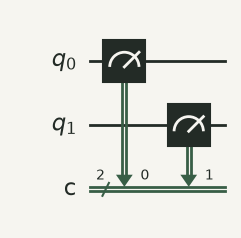

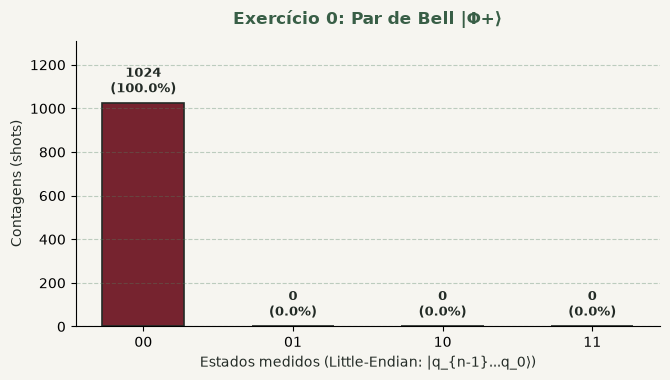

In [14]:
qc_bell = QuantumCircuit(2, 2)

# TODO: Aplique H no qubit 0 e CNOT(0, 1)


qc_bell.measure([0, 1], [0, 1])
display(qc_bell.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))

counts = simular(qc_bell)
plotar_histograma(counts, "Exercício 0: Par de Bell |Φ+⟩")

---
## Exercício 1: Codificação Superdensa (*Superdense Coding*)
Envie 2 bits clássicos (`mensagem`) aplicando portas apenas no qubit `0` da Alice:
* `'00'` $\to$ nada | `'01'` $\to$ `qc.z(0)` | `'10'` $\to$ `qc.x(0)` | `'11'` $\to$ `qc.x(0)` e `qc.z(0)`

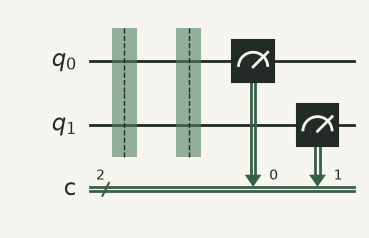

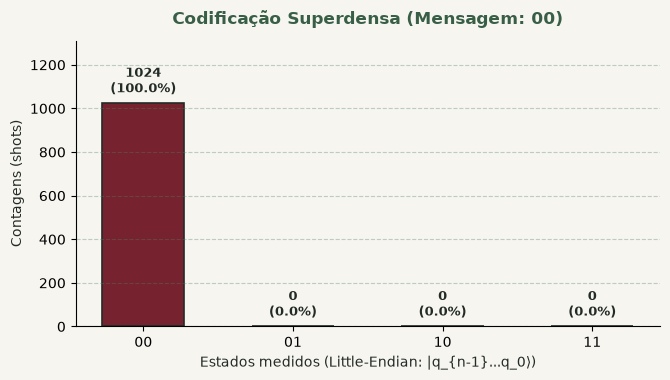

In [15]:
mensagem = "00"  # Depois de completar os TODOs, teste com "01", "10" e "11"
qc_sd = QuantumCircuit(2, 2)

# 1. Par de Bell entre Alice (q0) e Bob (q1)
# TODO: Crie o par de Bell aplicando H no qubit 0 e CNOT(0, 1)

qc_sd.barrier()

# 2. Codificação de Alice em q0
if mensagem == "01":
    pass  # TODO: Aplique a porta Z no qubit 0
elif mensagem == "10":
    pass  # TODO: Aplique a porta X no qubit 0
elif mensagem == "11":
    pass  # TODO: Aplique a porta X e depois a porta Z no qubit 0
qc_sd.barrier()

# 3. Decodificação de Bob e medição
# TODO: Decodifique aplicando CNOT(0, 1) e depois H no qubit 0

qc_sd.measure([0, 1], [0, 1])

display(qc_sd.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))
plotar_histograma(simular(qc_sd), f"Codificação Superdensa (Mensagem: {mensagem})")

---
## Exercício 2: Teletransporte Quântico
Transfira o estado de $q_0$ para $q_2$ completando:
1. Par de Bell entre $q_1$ e $q_2$: `qc_tel.h(1)` e `qc_tel.cx(1, 2)`
2. Alice emaranha $q_0$ e $q_1$: `qc_tel.cx(0, 1)` e `qc_tel.h(0)`
3. Correções de Bob em $q_2$: `qc_tel.cx(1, 2)` e `qc_tel.cz(0, 2)`

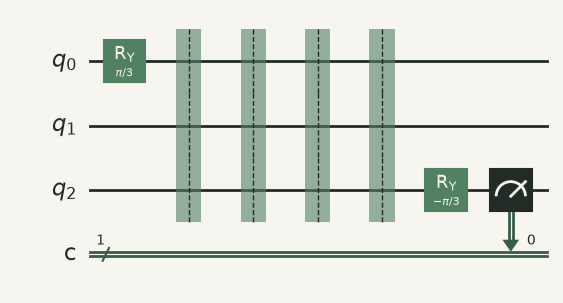

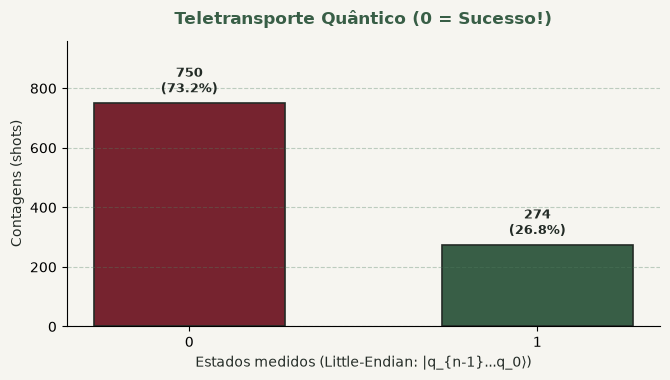

In [16]:
qc_tel = QuantumCircuit(3, 1)

# 1. Estado inicial secreto em q0
qc_tel.ry(np.pi / 3, 0)
qc_tel.barrier()

# 2. TODO: Crie o par de Bell entre q1 e q2 (h em 1, cx de 1 para 2)

qc_tel.barrier()

# 3. TODO: Alice emaranha q0 com q1 (cx de 0 para 1, h em 0)

qc_tel.barrier()

# 4. TODO: Bob corrige q2 (cx de 1 para 2, cz de 0 para 2)

qc_tel.barrier()

# 5. Verificação inversa: se medir '0' com 100%, o estado foi teletransportado!
qc_tel.ry(-np.pi / 3, 2)
qc_tel.measure(2, 0)

display(qc_tel.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))
plotar_histograma(simular(qc_tel), "Teletransporte Quântico (0 = Sucesso!)", estados_destaque=["0"])

---
## Exercício 3: Algoritmo de Busca de Grover ($n = 2$ Qubits)
**Objetivo:** Encontrar o estado secreto $\ket{\omega} = \ket{11}$ dentre $N = 4$ estados com **apenas 1 consulta** ao oráculo!

### Os 3 Blocos do Circuito:
1. **Superposição Inicial:** `qc_grover.h([0, 1])`
2. **Oráculo de Fase para $\ket{11}$:** Inverte o sinal de $\ket{11}$ usando `qc_grover.cz(0, 1)`.
3. **Difusor de Grover ($U_s$):**
   * `qc_grover.h([0, 1])`
   * `qc_grover.x([0, 1])`
   * `qc_grover.cz(0, 1)`
   * `qc_grover.x([0, 1])`
   * `qc_grover.h([0, 1])`

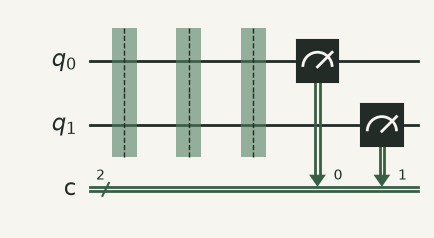

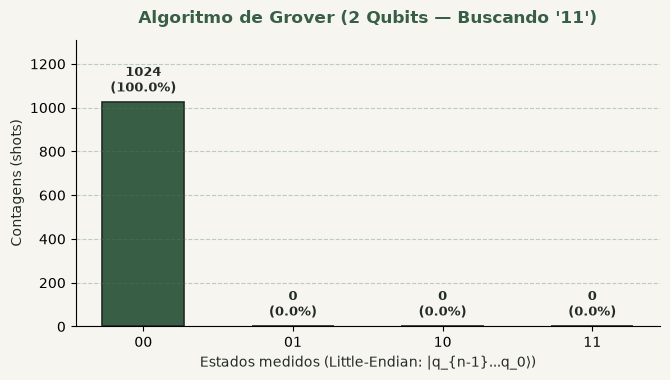

In [17]:
qc_grover = QuantumCircuit(2, 2)

# ETAPA 1: Superposição uniforme em todos os qubits
# TODO: Aplique Hadamard (H) nos qubits [0, 1]

qc_grover.barrier()

# ETAPA 2: Oráculo que marca o estado |11⟩ com fase negativa (-|11⟩)
# TODO: Aplique a porta Controlled-Z: qc_grover.cz(0, 1)

qc_grover.barrier()

# ETAPA 3: Difusor de Grover (Inversão em torno da média)
# TODO: Aplique H -> X -> CZ -> X -> H nos qubits [0, 1]

qc_grover.barrier()

# Medição final
qc_grover.measure([0, 1], [0, 1])
display(qc_grover.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))

counts_grover = simular(qc_grover)
plotar_histograma(counts_grover, "Algoritmo de Grover (2 Qubits — Buscando '11')", estados_destaque=["11"])

---
## Exercício 4: Grover com Somador de Cuccaro ($n = 2$ Bits — $A + Y = X$)
**Objetivo:** Descobrir qual número **$A \in \{0, 1, 2, 3\}$** somado com **$Y = 1$ (`'01'`)** resulta em **$X = 3$ (`'11'`)**:
$$A + 1 = 3 \implies A = 2 \text{ (\texttt{'10'} em binário)}$$

### Como funciona a porta `CDKMRippleCarryAdder(2, kind="fixed")`?
Ela usa $2n + 1 = 5$ qubits para somar dois números de 2 bits reversivelmente ($\ket{A}\ket{B}\ket{0} \to \ket{A}\ket{A+B}\ket{0}$):
* **Qubits `0, 1`:** Registrador **$A$** (incógnita colocada em superposição)
* **Qubits `2, 3`:** Registrador **$B$** (inicializado com $Y = 1$, recebe a soma $A + Y$)
* **Qubit `4`:** Qubit auxiliar (`help` em $\ket{0}$)

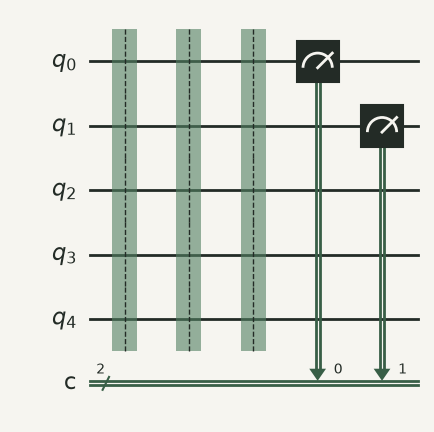

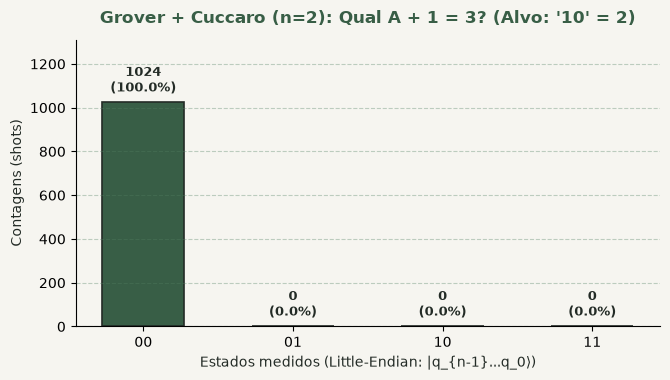

In [18]:
somador = CDKMRippleCarryAdder(2, kind="fixed")
qc_cuccaro = QuantumCircuit(5, 2)  # q0,q1 = A | q2,q3 = Y | q4 = aux

# 1. Inicializa Y = 1 ('01' -> porta X em q2) e coloca A (q0, q1) em superposição
# TODO: Aplique X no qubit 2 (para definir Y = 1) e H nos qubits [0, 1] (superposição em A)

qc_cuccaro.barrier()

# 2. ORÁCULO COM SOMADOR DE CUCCARO (Soma -> Marca X=3 -> Descomputa)
# TODO a): Aplique o somador nos qubits [0, 1, 2, 3, 4]: qc_cuccaro.append(somador, [0, 1, 2, 3, 4])

# TODO b): Marque a soma X = 3 ('11') no registrador B (qubits 2 e 3): qc_cuccaro.cz(2, 3)

# TODO c): Descompute a soma com somador.inverse() em [0, 1, 2, 3, 4]: qc_cuccaro.append(somador.inverse(), [0, 1, 2, 3, 4])
qc_cuccaro.barrier()

# 3. DIFUSOR DE GROVER EM A (qubits 0 e 1)
# TODO d): Aplique H -> X -> CZ -> X -> H nos qubits [0, 1]

qc_cuccaro.barrier()

# 4. Mede o registrador A (qubits 0 e 1)
qc_cuccaro.measure([0, 1], [0, 1])
display(qc_cuccaro.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))

counts_cuc = simular(qc_cuccaro)
plotar_histograma(counts_cuc, "Grover + Cuccaro (n=2): Qual A + 1 = 3? (Alvo: '10' = 2)", estados_destaque=["10"])